#Projeto Aplicado I - Universidade Presbiteriana Mackenzie

##Banco Central do Brasil

###Grupo:
| Nome | RA | E-mail |
| :--- | :---: | :--- |
| Lucas Pacola | 10775499 | lucaspacola.lp@gmail.com |
| Rafaela Almeida | 10763903 | fkngrafa20@gmail.com |
| Roberto Valentini | 10778375 | robertovalentinibt@gmail.com |
| Rodrigo Lemos | 10776362 | rodrigolemos49@gmail.com |


Github: https://github.com/Rodslemos/ProjetodadosMack

###Import dos pacotes a serem utilizados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests

###Import dos Datasets

In [ ]:
#URL das bases
url_mensal = 'https://github.com/Rodslemos/ProjetodadosMack/raw/refs/heads/main/Projeto%20Aplicado/Dataset/Bronze/Meios%20de%20pagamentos%20mensal.xlsx'
url_tri = 'https://github.com/Rodslemos/ProjetodadosMack/raw/refs/heads/main/Projeto%20Aplicado/Dataset/Bronze/Meios%20de%20pagamentos%20trimestral.xlsx'


# Lê o arquivo Excel utilizando o Pandas e atribui a uma variavel
df_mes = pd.read_excel(url_mensal)
df_tri = pd.read_excel(url_tri)

In [ ]:
#Primeiras linhas do Dataset mensal
df_mes.head()

,AnoMes,quantidadePix,valorPix,quantidadeTED,valorTED,quantidadeTEC,valorTEC,quantidadeCheque,valorCheque,quantidadeBoleto,valorBoleto,quantidadeDOC,valorDOC
0,202607,7975215.70,3801018.76,68602.77,4058803.01,0.0,0.0,6607.51,30011.40,341104.26,577982.13,0.0,0.0
1,202606,7699815.65,3599273.42,64041.78,4235160.17,0.0,0.0,6693.47,30773.59,340587.57,577082.91,0.0,0.0
2,202605,7854699.48,3478038.27,65540.90,3828232.89,0.0,0.0,6299.28,28997.49,321873.66,541107.26,0.0,0.0
3,202604,7370602.06,3421737.84,65272.11,4064285.57,0.0,0.0,6667.11,32464.83,326984.42,552159.56,0.0,0.0
4,202603,7442903.15,3533664.12,69211.12,4196796.01,0.0,0.0,7367.69,32865.28,346881.81,572564.03,0.0,0.0


In [ ]:
#Primeiras linhas do Dataset trimestral]
df_tri.head()

,datatrimestre,valorPix,valorCartaoCredito,valorCartaoDebito,valorCartaoPrePago,quantidadePix,quantidadeCartaoCredito,quantidadeCartaoDebito,quantidadeCartaoPrePago
0,2026-06-30,10499049.52,815569.50,235419.04,87023.46,22925117.19,6049737.23,4076645.48,2211207.34
1,2026-03-31,9701493.35,814134.53,227630.17,83788.47,21071015.63,6060463.09,3966315.80,2151539.24
2,2025-12-31,10209705.55,832271.20,253820.31,95019.14,22282468.70,6139633.62,4303573.50,2383749.09
3,2025-09-30,9267955.38,765312.61,235731.58,86563.39,20480993.48,5860367.55,4086373.58,2249615.33
4,2025-06-30,8358247.94,734027.50,236373.91,84160.25,19353790.72,5658871.23,4030175.37,2182537.24


###Tipos de dados

In [ ]:
#Verificando os tipos de dados das tabelas

print('Tipos de dados do Dataset mensal')
print(df_mes.dtypes)
print('\n')
print('Tipos de dados do Dataset trimestral')
print(df_tri.dtypes)

Tipos de dados do Dataset mensal
AnoMes                int64
quantidadePix       float64
valorPix            float64
quantidadeTED       float64
valorTED            float64
quantidadeTEC       float64
valorTEC            float64
quantidadeCheque    float64
valorCheque         float64
quantidadeBoleto    float64
valorBoleto         float64
quantidadeDOC       float64
valorDOC            float64
dtype: object


Tipos de dados do Dataset trimestral
datatrimestre              datetime64[ns]
valorPix                          float64
valorCartaoCredito                float64
valorCartaoDebito                 float64
valorCartaoPrePago                float64
quantidadePix                     float64
quantidadeCartaoCredito           float64
quantidadeCartaoDebito            float64
quantidadeCartaoPrePago           float64
dtype: object


###Verificação de dados faltantes, nulos ou zerados

In [ ]:
# Contagem de valores nulos/faltantes (NaN ou None) por coluna
print("--- Valores Nulos/Faltantes do df_mes ---")
print(df_mes.isna().sum())
print("--- Valores Nulos/Faltantes do df_tri ---")
print(df_tri.isna().sum())

# Contagem de valores exatamente iguais a 0 por coluna
print("\n--- Valores Zerados (0) do df_mes ---")
print((df_mes == 0).sum())
print("\n--- Valores Zerados (0) do df_tri ---")
print((df_tri == 0).sum())

--- Valores Nulos/Faltantes do df_mes ---
AnoMes              0
quantidadePix       0
valorPix            0
quantidadeTED       0
valorTED            0
quantidadeTEC       0
valorTEC            0
quantidadeCheque    0
valorCheque         0
quantidadeBoleto    0
valorBoleto         0
quantidadeDOC       0
valorDOC            0
dtype: int64
--- Valores Nulos/Faltantes do df_tri ---
datatrimestre              0
valorPix                   0
valorCartaoCredito         0
valorCartaoDebito          0
valorCartaoPrePago         0
quantidadePix              0
quantidadeCartaoCredito    0
quantidadeCartaoDebito     0
quantidadeCartaoPrePago    0
dtype: int64

--- Valores Zerados (0) do df_mes ---
AnoMes               0
quantidadePix        0
valorPix             0
quantidadeTED        0
valorTED             0
quantidadeTEC       29
valorTEC            29
quantidadeCheque     0
valorCheque          0
quantidadeBoleto     0
valorBoleto          0
quantidadeDOC       29
valorDOC            29
dtype

###Ajustes e criação de bases Silver para uso

####Ajustes no df_mes e criação de base Silver

In [ ]:
#Exclusão do período que não será utilizado e datas em ordem crescente
df_mes_silver = df_mes[df_mes['AnoMes'] <= 202512].copy()
df_mes_silver.sort_values(by='AnoMes', inplace=True)
df_mes_silver.head()

,AnoMes,quantidadePix,valorPix,quantidadeTED,valorTED,quantidadeTEC,valorTEC,quantidadeCheque,valorCheque,quantidadeBoleto,valorBoleto,quantidadeDOC,valorDOC
66,202101,199611.49,156576.83,119389.99,2406059.95,801.69,1582.47,18870.96,47363.18,314232.62,351809.62,14474.54,8834.15
65,202102,273167.83,195464.50,111617.80,2381021.03,740.59,1497.10,17997.84,46939.40,306432.32,338584.62,8622.89,6384.33
64,202103,389558.55,273005.19,119890.41,3083743.42,638.88,1272.87,21076.69,57274.71,358045.89,399875.90,8589.92,6559.22
63,202104,494733.64,312912.45,110989.05,2735892.74,693.38,1446.80,18441.84,52999.98,335530.74,374186.91,7535.06,5755.89
62,202105,641530.48,376521.08,110651.80,2819281.60,489.86,983.25,18456.48,54201.28,341731.09,389564.26,10221.54,8444.29


In [ ]:
#Equalização das unidades de medidas, passando tudo para milhões

# Identifica as colunas de quantidade
colunas_qtd = [col for col in df_mes_silver.columns if col.startswith('quantidade')]

# Divide por 1.000 para converter de "Mil" para "Milhões"
df_mes_silver[colunas_qtd] = df_mes_silver[colunas_qtd] / 1000

df_mes_silver.head()

,AnoMes,quantidadePix,valorPix,quantidadeTED,valorTED,quantidadeTEC,valorTEC,quantidadeCheque,valorCheque,quantidadeBoleto,valorBoleto,quantidadeDOC,valorDOC
66,202101,199.61149,156576.83,119.38999,2406059.95,0.80169,1582.47,18.87096,47363.18,314.23262,351809.62,14.47454,8834.15
65,202102,273.16783,195464.50,111.61780,2381021.03,0.74059,1497.10,17.99784,46939.40,306.43232,338584.62,8.62289,6384.33
64,202103,389.55855,273005.19,119.89041,3083743.42,0.63888,1272.87,21.07669,57274.71,358.04589,399875.90,8.58992,6559.22
63,202104,494.73364,312912.45,110.98905,2735892.74,0.69338,1446.80,18.44184,52999.98,335.53074,374186.91,7.53506,5755.89
62,202105,641.53048,376521.08,110.65180,2819281.60,0.48986,983.25,18.45648,54201.28,341.73109,389564.26,10.22154,8444.29


In [ ]:
#Criação de colunas de média de valores por transação para cada tipo

#Média por Pix
df_mes_silver['mediaPix'] = df_mes_silver['valorPix'] / df_mes_silver['quantidadePix']
#Média por TED
df_mes_silver['mediaTED'] = df_mes_silver['valorTED'] / df_mes_silver['quantidadeTED']
#Média por TEC
df_mes_silver['mediaTEC'] = df_mes_silver['valorTEC'] / df_mes_silver['quantidadeTEC']
#Média por Cheque
df_mes_silver['mediaCheque'] = df_mes_silver['valorCheque'] / df_mes_silver['quantidadeCheque']
#Média por Boleto
df_mes_silver['mediaBoleto'] = df_mes_silver['valorBoleto'] / df_mes_silver['quantidadeBoleto']
#Média por DOC
df_mes_silver['mediaDOC'] = df_mes_silver['valorDOC'] / df_mes_silver['quantidadeDOC']

df_mes_silver.head()

,AnoMes,quantidadePix,valorPix,quantidadeTED,valorTED,quantidadeTEC,valorTEC,quantidadeCheque,valorCheque,quantidadeBoleto,valorBoleto,quantidadeDOC,valorDOC,mediaPix,mediaTED,mediaTEC,mediaCheque,mediaBoleto,mediaDOC
66,202101,199.61149,156576.83,119.38999,2406059.95,0.80169,1582.47,18.87096,47363.18,314.23262,351809.62,14.47454,8834.15,784.407902,20152.945402,1973.917599,2509.844756,1119.583384,610.323368
65,202102,273.16783,195464.50,111.61780,2381021.03,0.74059,1497.10,17.99784,46939.40,306.43232,338584.62,8.62289,6384.33,715.547288,21331.911487,2021.496375,2608.057411,1104.924637,740.393302
64,202103,389.55855,273005.19,119.89041,3083743.42,0.63888,1272.87,21.07669,57274.71,358.04589,399875.90,8.58992,6559.22,700.806567,25721.351858,1992.345980,2717.443299,1116.828628,763.595004
63,202104,494.73364,312912.45,110.98905,2735892.74,0.69338,1446.80,18.44184,52999.98,335.53074,374186.91,7.53506,5755.89,632.486705,24650.114043,2086.590326,2873.898700,1115.209027,763.881110
62,202105,641.53048,376521.08,110.65180,2819281.60,0.48986,983.25,18.45648,54201.28,341.73109,389564.26,10.22154,8444.29,586.910664,25478.858907,2007.206141,2936.707324,1139.973129,826.126983


####Ajustes no df_tri e criação de base Silver


In [ ]:
#Exclusão do período que não será utilizado e data em ordem crescente

df_tri_silver = df_tri[df_tri['datatrimestre'] <= '2025-12-31'].copy()
df_tri_silver.sort_values(by='datatrimestre', inplace=True)
df_tri_silver.head()

,datatrimestre,valorPix,valorCartaoCredito,valorCartaoDebito,valorCartaoPrePago,quantidadePix,quantidadeCartaoCredito,quantidadeCartaoDebito,quantidadeCartaoPrePago
21,2021-03-31,625046.52,309999.59,204752.91,19905.00,862337.86,2582363.34,3005004.65,378355.44
20,2021-06-30,1105735.21,344339.59,214381.06,26202.57,1871563.89,2839315.36,3141691.41,543360.38
19,2021-09-30,1556916.22,398440.24,233970.03,33194.10,2863336.94,3308864.10,3526062.88,733877.30
18,2021-12-31,1916418.68,467037.92,257458.30,42051.56,3836285.60,3737883.65,3849208.18,928575.95
17,2022-03-31,2067826.55,452804.72,230186.87,42830.26,4250023.75,3677384.06,3589968.33,983577.33


In [ ]:
#Criação de coluna de trimestre em outra notação

#Garante que a coluna esteja no formato datetime
df_tri_silver['datatrimestre'] = pd.to_datetime(df_tri_silver['datatrimestre'])

#Cria a coluna 'AnoTri' no formato '2025Q4' e substitui o 'Q' por 'T'
df_tri_silver['AnoTri'] = df_tri_silver['datatrimestre'].dt.to_period('Q').astype(str).str.replace('Q', 'T')

df_tri_silver.head()


,datatrimestre,valorPix,valorCartaoCredito,valorCartaoDebito,valorCartaoPrePago,quantidadePix,quantidadeCartaoCredito,quantidadeCartaoDebito,quantidadeCartaoPrePago,AnoTri
21,2021-03-31,625046.52,309999.59,204752.91,19905.00,862337.86,2582363.34,3005004.65,378355.44,2021T1
20,2021-06-30,1105735.21,344339.59,214381.06,26202.57,1871563.89,2839315.36,3141691.41,543360.38,2021T2
19,2021-09-30,1556916.22,398440.24,233970.03,33194.10,2863336.94,3308864.10,3526062.88,733877.30,2021T3
18,2021-12-31,1916418.68,467037.92,257458.30,42051.56,3836285.60,3737883.65,3849208.18,928575.95,2021T4
17,2022-03-31,2067826.55,452804.72,230186.87,42830.26,4250023.75,3677384.06,3589968.33,983577.33,2022T1


In [ ]:
#Equalização das unidades de medidas, passando tudo para milhões

# Identifica as colunas de quantidade
colunas_qtd = [col for col in df_tri_silver.columns if col.startswith('quantidade')]

# Divide por 1.000 para converter de "Mil" para "Milhões"
df_tri_silver[colunas_qtd] = df_tri_silver[colunas_qtd] / 1000

df_tri_silver.head()

,datatrimestre,valorPix,valorCartaoCredito,valorCartaoDebito,valorCartaoPrePago,quantidadePix,quantidadeCartaoCredito,quantidadeCartaoDebito,quantidadeCartaoPrePago,AnoTri
21,2021-03-31,625046.52,309999.59,204752.91,19905.00,862.33786,2582.36334,3005.00465,378.35544,2021T1
20,2021-06-30,1105735.21,344339.59,214381.06,26202.57,1871.56389,2839.31536,3141.69141,543.36038,2021T2
19,2021-09-30,1556916.22,398440.24,233970.03,33194.10,2863.33694,3308.86410,3526.06288,733.87730,2021T3
18,2021-12-31,1916418.68,467037.92,257458.30,42051.56,3836.28560,3737.88365,3849.20818,928.57595,2021T4
17,2022-03-31,2067826.55,452804.72,230186.87,42830.26,4250.02375,3677.38406,3589.96833,983.57733,2022T1


In [ ]:
#Criação de colunas de média de valores por transação para cada tipo

#Média por Pix
df_tri_silver['mediaPix'] = df_tri_silver['valorPix'] / df_tri_silver['quantidadePix']
#Média por Cartão de Credito
df_tri_silver['mediaCartaoCredito'] = df_tri_silver['valorCartaoCredito'] / df_tri_silver['quantidadeCartaoCredito']
#Média por Cartão de Debito
df_tri_silver['mediaCartaoDebito'] = df_tri_silver['valorCartaoDebito'] / df_tri_silver['quantidadeCartaoDebito']
#Média por Cartão Pré Pago
df_tri_silver['mediaCartaoPrePago'] = df_tri_silver['valorCartaoPrePago'] / df_tri_silver['quantidadeCartaoPrePago']

df_tri_silver.head()

,datatrimestre,valorPix,valorCartaoCredito,valorCartaoDebito,valorCartaoPrePago,quantidadePix,quantidadeCartaoCredito,quantidadeCartaoDebito,quantidadeCartaoPrePago,AnoTri,mediaPix,mediaCartaoCredito,mediaCartaoDebito,mediaCartaoPrePago
21,2021-03-31,625046.52,309999.59,204752.91,19905.00,862.33786,2582.36334,3005.00465,378.35544,2021T1,724.827877,120.044916,68.137302,52.609261
20,2021-06-30,1105735.21,344339.59,214381.06,26202.57,1871.56389,2839.31536,3141.69141,543.36038,2021T2,590.808156,121.275570,68.237466,48.223188
19,2021-09-30,1556916.22,398440.24,233970.03,33194.10,2863.33694,3308.86410,3526.06288,733.87730,2021T3,543.741883,120.416018,66.354469,45.231131
18,2021-12-31,1916418.68,467037.92,257458.30,42051.56,3836.28560,3737.88365,3849.20818,928.57595,2021T4,499.550576,124.947153,66.886042,45.286075
17,2022-03-31,2067826.55,452804.72,230186.87,42830.26,4250.02375,3677.38406,3589.96833,983.57733,2022T1,486.544705,123.132290,64.119471,43.545392


#Gráficos

####Quantidade de transações por meio de pagamento por mês

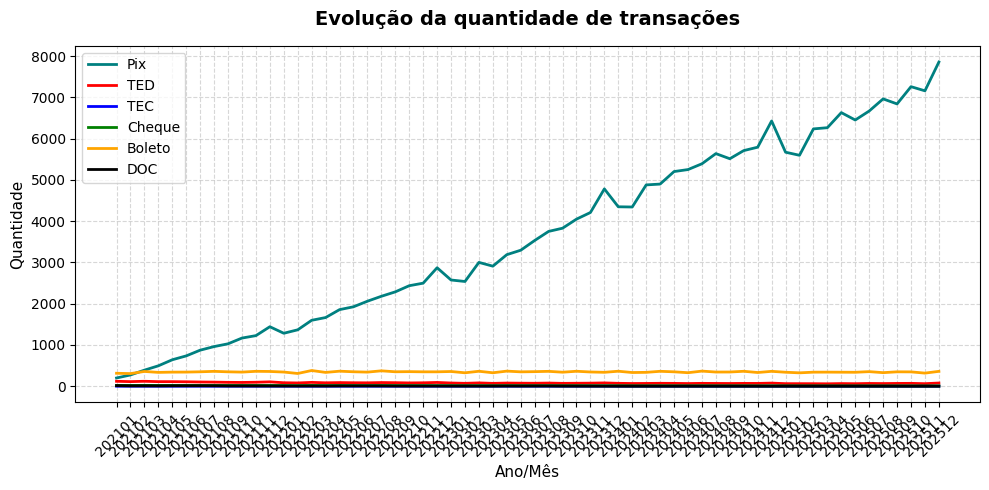

In [ ]:
# 1. CRIAR A FIGURA E OS EIXOS
# fig = a tela completa | ax = a área do gráfico
fig, ax = plt.subplots(figsize=(10, 5))

# 2. PLOTAR OS DADOS
# ax.plot(), ax.bar(), ax.scatter(), ax.hist(), etc.
ax.plot(df_mes_silver['AnoMes'].astype(str), df_mes_silver['quantidadePix'], label='Pix', color='teal', linewidth=2)
ax.plot(df_mes_silver['AnoMes'].astype(str), df_mes_silver['quantidadeTED'], label='TED', color='red', linewidth=2)
ax.plot(df_mes_silver['AnoMes'].astype(str), df_mes_silver['quantidadeTEC'], label='TEC', color='blue', linewidth=2)
ax.plot(df_mes_silver['AnoMes'].astype(str), df_mes_silver['quantidadeCheque'], label='Cheque', color='green', linewidth=2)
ax.plot(df_mes_silver['AnoMes'].astype(str), df_mes_silver['quantidadeBoleto'], label='Boleto', color='orange', linewidth=2)
ax.plot(df_mes_silver['AnoMes'].astype(str), df_mes_silver['quantidadeDOC'], label='DOC', color='black', linewidth=2)

# 3. PERSONALIZAR O GRÁFICO (Títulos, Rótulos, Grade e Limites)
ax.set_title('Evolução da quantidade de transações', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Ano/Mês', fontsize=11)
ax.set_ylabel('Quantidade', fontsize=11)

# Rotacionar rótulos do eixo X para não sobrepor
plt.xticks(rotation=45)

# Adicionar grade e legenda
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='upper left')

# 4. AJUSTAR LAYOUT E EXIBIR
plt.tight_layout() # Evita cortar rótulos nas bordas
plt.show()

####Valor movimentado por mês por meio de pagamento

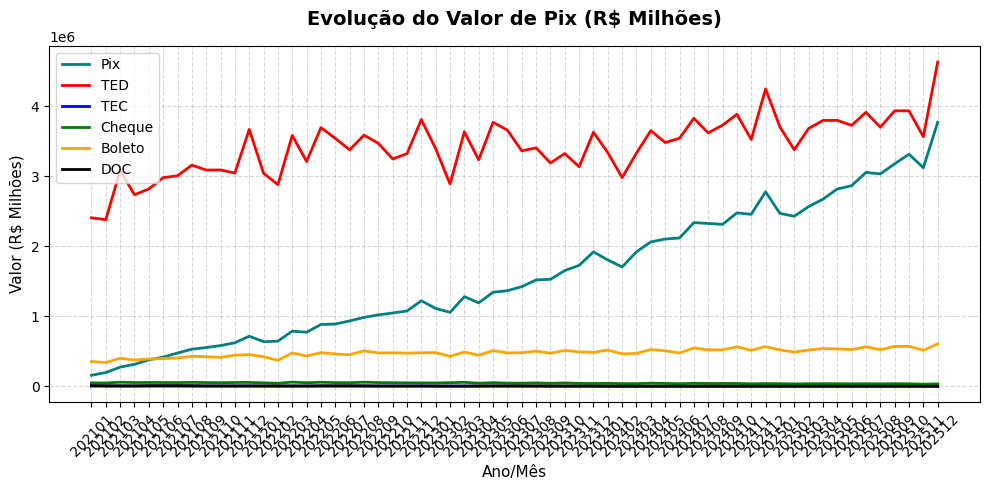

In [ ]:
# 1. CRIAR A FIGURA E OS EIXOS
# fig = a tela completa | ax = a área do gráfico
fig, ax = plt.subplots(figsize=(10, 5))

# 2. PLOTAR OS DADOS
# ax.plot(), ax.bar(), ax.scatter(), ax.hist(), etc.
ax.plot(df_mes_silver['AnoMes'].astype(str), df_mes_silver['valorPix'], label='Pix', color='teal', linewidth=2)
ax.plot(df_mes_silver['AnoMes'].astype(str), df_mes_silver['valorTED'], label='TED', color='red', linewidth=2)
ax.plot(df_mes_silver['AnoMes'].astype(str), df_mes_silver['valorTEC'], label='TEC', color='blue', linewidth=2)
ax.plot(df_mes_silver['AnoMes'].astype(str), df_mes_silver['valorCheque'], label='Cheque', color='green', linewidth=2)
ax.plot(df_mes_silver['AnoMes'].astype(str), df_mes_silver['valorBoleto'], label='Boleto', color='orange', linewidth=2)
ax.plot(df_mes_silver['AnoMes'].astype(str), df_mes_silver['valorDOC'], label='DOC', color='black', linewidth=2)

# 3. PERSONALIZAR O GRÁFICO (Títulos, Rótulos, Grade e Limites)
ax.set_title('Evolução do Valor Movimentado (R$ Milhões)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Ano/Mês', fontsize=11)
ax.set_ylabel('Valor (R$ Milhões)', fontsize=11)

# Rotacionar rótulos do eixo X para não sobrepor
plt.xticks(rotation=45)

# Adicionar grade e legenda
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='upper left')

# 4. AJUSTAR LAYOUT E EXIBIR
plt.tight_layout() # Evita cortar rótulos nas bordas
plt.show()

####Média por transação por mês

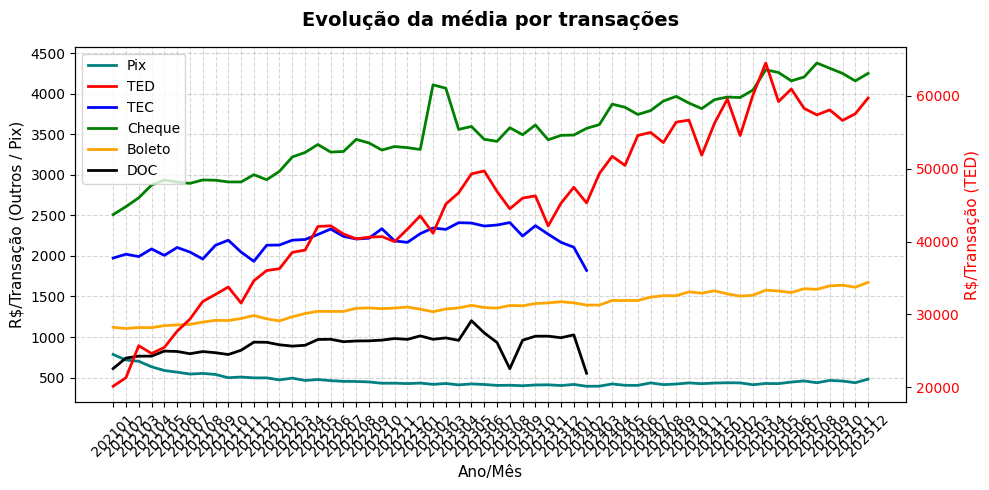

In [ ]:
# 1. CRIAR A FIGURA E O EIXO PRINCIPAL (Esquerda)
fig, ax1 = plt.subplots(figsize=(10, 5))

# 2. CRIAR O EIXO SECUNDÁRIO (Direita)
ax2 = ax1.twinx()

# 3. PLOTAR OS DADOS
# Pix e demais meios no eixo principal (ax1)
l1 = ax1.plot(df_mes_silver['AnoMes'].astype(str), df_mes_silver['mediaPix'], label='Pix', color='teal', linewidth=2)
l3 = ax1.plot(df_mes_silver['AnoMes'].astype(str), df_mes_silver['mediaTEC'], label='TEC', color='blue', linewidth=2)
l4 = ax1.plot(df_mes_silver['AnoMes'].astype(str), df_mes_silver['mediaCheque'], label='Cheque', color='green', linewidth=2)
l5 = ax1.plot(df_mes_silver['AnoMes'].astype(str), df_mes_silver['mediaBoleto'], label='Boleto', color='orange', linewidth=2)
l6 = ax1.plot(df_mes_silver['AnoMes'].astype(str), df_mes_silver['mediaDOC'], label='DOC', color='black', linewidth=2)

# TED no eixo secundário (ax2)
l2 = ax2.plot(df_mes_silver['AnoMes'].astype(str), df_mes_silver['mediaTED'], label='TED', color='red', linewidth=2)

# 4. PERSONALIZAR TÍTULO E RÓTULOS
ax1.set_title('Evolução da média por transações', fontsize=14, fontweight='bold', pad=15)
ax1.set_xlabel('Ano/Mês', fontsize=11)

# Rótulos e cores dos eixos Y
ax1.set_ylabel('R$/Transação (Outros / Pix)', fontsize=11)
ax2.set_ylabel('R$/Transação (TED)', fontsize=11, color='red')
ax2.tick_params(axis='y', labelcolor='red')  # Destaque em vermelho nos valores do TED

# Rotacionar rótulos do eixo X
ax1.tick_params(axis='x', rotation=45)

# Adicionar grade no eixo principal
ax1.grid(True, linestyle='--', alpha=0.5)

# 5. UNIFICAR A LEGENDA DOS DOIS EIXOS
lines = l1 + l2 + l3 + l4 + l5 + l6
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left')

# 6. AJUSTAR LAYOUT E EXIBIR
plt.tight_layout()
plt.show()

####Quantidade de transações por meio de pagamento por trimestre



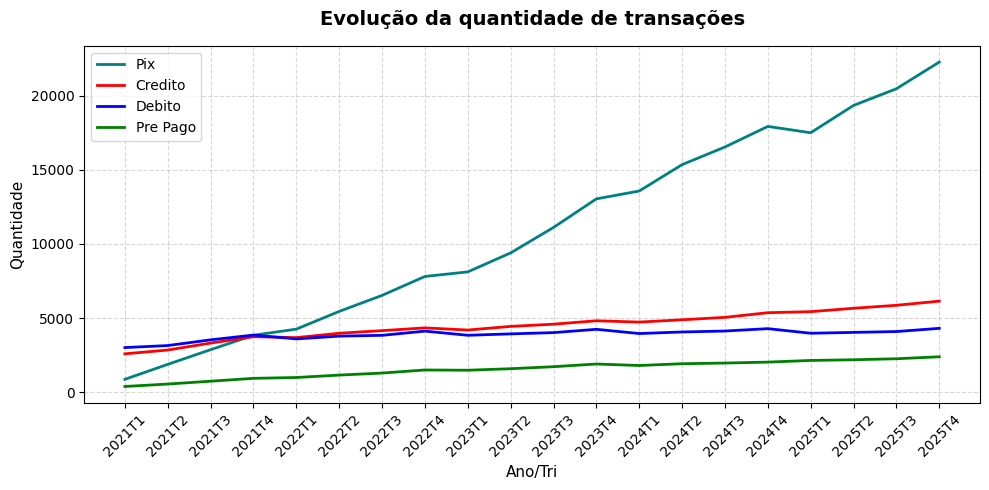

In [ ]:
# 1. CRIAR A FIGURA E OS EIXOS
# fig = a tela completa | ax = a área do gráfico
fig, ax = plt.subplots(figsize=(10, 5))

# 2. PLOTAR OS DADOS
# ax.plot(), ax.bar(), ax.scatter(), ax.hist(), etc.
ax.plot(df_tri_silver['AnoTri'].astype(str), df_tri_silver['quantidadePix'], label='Pix', color='teal', linewidth=2)
ax.plot(df_tri_silver['AnoTri'].astype(str), df_tri_silver['quantidadeCartaoCredito'], label='Credito', color='red', linewidth=2)
ax.plot(df_tri_silver['AnoTri'].astype(str), df_tri_silver['quantidadeCartaoDebito'], label='Debito', color='blue', linewidth=2)
ax.plot(df_tri_silver['AnoTri'].astype(str), df_tri_silver['quantidadeCartaoPrePago'], label='Pre Pago', color='green', linewidth=2)


# 3. PERSONALIZAR O GRÁFICO (Títulos, Rótulos, Grade e Limites)
ax.set_title('Evolução da quantidade de transações', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Ano/Tri', fontsize=11)
ax.set_ylabel('Quantidade', fontsize=11)

# Rotacionar rótulos do eixo X para não sobrepor
plt.xticks(rotation=45)

# Adicionar grade e legenda
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='upper left')

# 4. AJUSTAR LAYOUT E EXIBIR
plt.tight_layout() # Evita cortar rótulos nas bordas
plt.show()

####Valor movimentado por trimestre por meio de pagamento

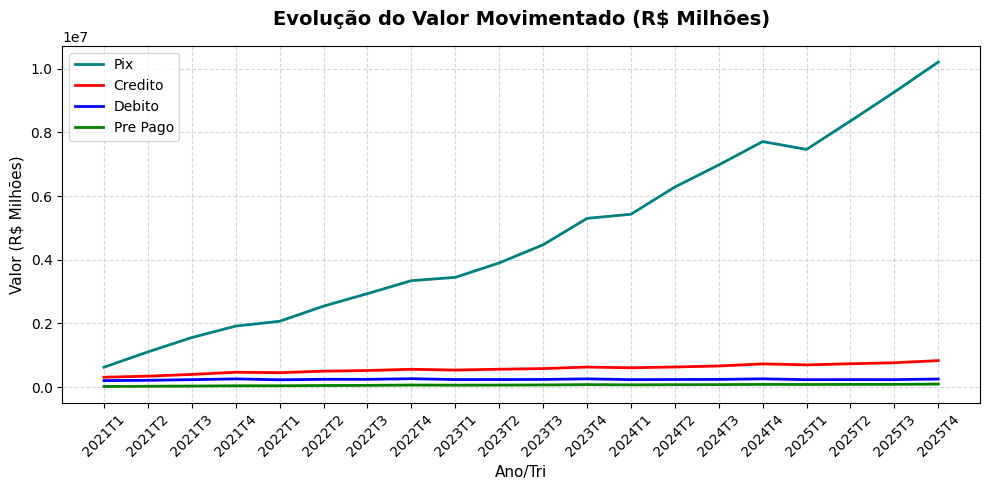

In [ ]:
# 1. CRIAR A FIGURA E OS EIXOS
# fig = a tela completa | ax = a área do gráfico
fig, ax = plt.subplots(figsize=(10, 5))

# 2. PLOTAR OS DADOS
# ax.plot(), ax.bar(), ax.scatter(), ax.hist(), etc.
ax.plot(df_tri_silver['AnoTri'].astype(str), df_tri_silver['valorPix'], label='Pix', color='teal', linewidth=2)
ax.plot(df_tri_silver['AnoTri'].astype(str), df_tri_silver['valorCartaoCredito'], label='Credito', color='red', linewidth=2)
ax.plot(df_tri_silver['AnoTri'].astype(str), df_tri_silver['valorCartaoDebito'], label='Debito', color='blue', linewidth=2)
ax.plot(df_tri_silver['AnoTri'].astype(str), df_tri_silver['valorCartaoPrePago'], label='Pre Pago', color='green', linewidth=2)


# 3. PERSONALIZAR O GRÁFICO (Títulos, Rótulos, Grade e Limites)
ax.set_title('Evolução do Valor Movimentado (R$ Milhões)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Ano/Tri', fontsize=11)
ax.set_ylabel('Valor (R$ Milhões)', fontsize=11)

# Rotacionar rótulos do eixo X para não sobrepor
plt.xticks(rotation=45)

# Adicionar grade e legenda
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='upper left')

# 4. AJUSTAR LAYOUT E EXIBIR
plt.tight_layout() # Evita cortar rótulos nas bordas
plt.show()

####Média por transação por trimestre

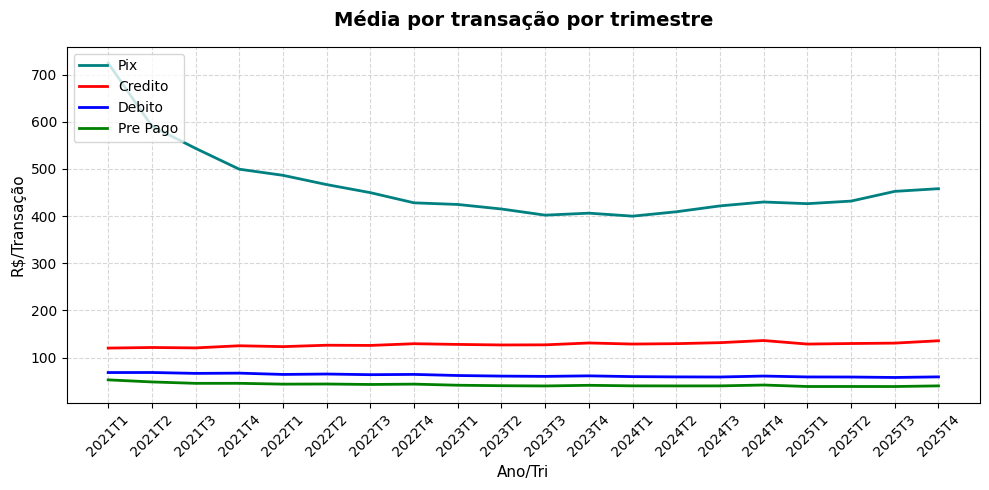

In [ ]:
# 1. CRIAR A FIGURA E OS EIXOS
# fig = a tela completa | ax = a área do gráfico
fig, ax = plt.subplots(figsize=(10, 5))

# 2. PLOTAR OS DADOS
# ax.plot(), ax.bar(), ax.scatter(), ax.hist(), etc.
ax.plot(df_tri_silver['AnoTri'].astype(str), df_tri_silver['mediaPix'], label='Pix', color='teal', linewidth=2)
ax.plot(df_tri_silver['AnoTri'].astype(str), df_tri_silver['mediaCartaoCredito'], label='Credito', color='red', linewidth=2)
ax.plot(df_tri_silver['AnoTri'].astype(str), df_tri_silver['mediaCartaoDebito'], label='Debito', color='blue', linewidth=2)
ax.plot(df_tri_silver['AnoTri'].astype(str), df_tri_silver['mediaCartaoPrePago'], label='Pre Pago', color='green', linewidth=2)


# 3. PERSONALIZAR O GRÁFICO (Títulos, Rótulos, Grade e Limites)
ax.set_title('Média por transação por trimestre', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Ano/Tri', fontsize=11)
ax.set_ylabel('R$/Transação', fontsize=11)

# Rotacionar rótulos do eixo X para não sobrepor
plt.xticks(rotation=45)

# Adicionar grade e legenda
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='upper left')

# 4. AJUSTAR LAYOUT E EXIBIR
plt.tight_layout() # Evita cortar rótulos nas bordas
plt.show()